## future changes robustness

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [ ]:
from scipy import stats

In [ ]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [ ]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [ ]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [ ]:
from functions import preproc_funcs as funcs

In [ ]:
from functions import xr_lowess

#### next steps - do the same for one large ensemble and the suite of CMIP6 models

In [ ]:
access_ts_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5o_ts.nc').ts.sel(time = slice('1850', '2100'))

In [ ]:
access_pr_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5o_pr.nc').pr.sel(time = slice('1850', '2100'))

In [ ]:
access_pr_ssp5['model'] = access_ts_ssp5['model']
access_pr_ssp3['model'] = access_ts_ssp3['model']
access_pr_ssp2['model'] = access_ts_ssp2['model']
access_pr_ssp1['model'] = access_ts_ssp1['model']
access_pr_ssp5o['model'] = access_ts_ssp5o['model']

In [ ]:
weights_access = np.cos(np.deg2rad(access_ts_ssp5.lat))
nino34_access_ssp5 = funcs.detrend_separate_check(access_ts_ssp5.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp3 = funcs.detrend_separate_check(access_ts_ssp3.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp2 = funcs.detrend_separate_check(access_ts_ssp2.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp1 = funcs.detrend_separate_check(access_ts_ssp1.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp5o = funcs.detrend_separate_check(access_ts_ssp5o.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')

In [ ]:
land_mask_access = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(access_pr_ssp5)
ar6_mask_access = regionmask.defined_regions.ar6.land.mask_3D(access_pr_ssp5.where(land_mask_access))

eaus_access_ssp5_anom = access_pr_ssp5.where(ar6_mask_access.isel(region=41)).mean(('lat', 'lon'))
eaus_access_ssp5_anom = access_pr_ssp5.where(ar6_mask_access.isel(region=41)).mean(('lat', 'lon'))

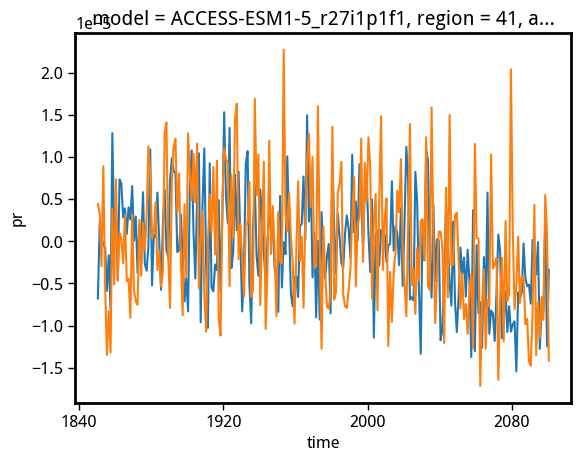

In [ ]:
eaus_access_anom.isel(model=0).plot()
eaus_access_anom.isel(model=-1).plot()

In [ ]:
eaus_access_det = funcs.detrend_separate_check(eaus_access_anom, dim='time', period=15)
eaus_access_std = eaus_access_det/eaus_access_det.std('time')

In [ ]:
obs_regr_20c, obs_pval_20c = funcs.get_regr_1d(nino34_obs.sel(time=slice('1900', '2000')), eaus_std.sel(time=slice('1900', '2000'))), funcs.get_pval_1d(nino34_obs.sel(time=slice('1900', '2000')), eaus_std.sel(time=slice('1900', '2000')))

In [ ]:
regr_20c_access = funcs.get_regr(nino34_access.sel(time=slice('1900', '2000')), eaus_access_std.sel(time=slice('1900', '2000')), dim='time')
pval_20c_access = funcs.get_pval(nino34_access.sel(time=slice('1900', '2000')), eaus_access_std.sel(time=slice('1900', '2000')), dim='time')

In [ ]:
regr_21c_access = funcs.get_regr(nino34_access.sel(time=slice('2000', '2100')), eaus_access_std.sel(time=slice('2000', '2100')), dim='time')
pval_21c_access = funcs.get_pval(nino34_access.sel(time=slice('2000', '2100')), eaus_access_std.sel(time=slice('2000', '2100')), dim='time')

<AxesSubplot:ylabel='Count'>

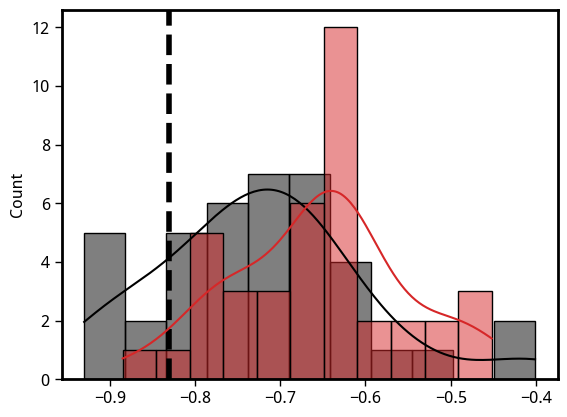

In [ ]:
plt.axvline(obs_regr_20c, color='k', ls='--', lw=4.0)
sns.histplot(regr_21c_access, bins=11, color='tab:red', alpha=0.5, kde=True)